# Customer Churn Analysis & Exploration

## Project objective
Explore a public telecom customer churn dataset to identify
customer characteristics associated with churn.

## Questions to investigate
1. What proportion of customers churn?
2. How does churn differ by contract type?
3. How does customer tenure relate to churn?
4. How do monthly charges differ between churned and retained customers?

## Tools
Python, Pandas, NumPy, Matplotlib, Seaborn, and Jupyter Notebook.

In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

print("Python interpreter:", sys.executable)
print("Pandas version:", pd.__version__)
print("Notebook setup successful!")

Python interpreter: c:\Users\Durvank Chavan\OneDrive\Desktop\CodeNova-AIML\codenova-customer-churn-analysis\.venv\Scripts\python.exe
Pandas version: 3.1.1
Notebook setup successful!


## 1. Dataset Source and Loading

Source: IBM Telco Customer Churn dataset, available on Kaggle.

Dataset page:
https://www.kaggle.com/datasets/blastchar/telco-customer-churn

This analysis examines customer characteristics associated with churn.

In [2]:
from pathlib import Path

filename = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

current_folder = Path.cwd()

if (current_folder / "data").is_dir():
    project_folder = current_folder
elif (current_folder.parent / "data").is_dir():
    project_folder = current_folder.parent
else:
    raise FileNotFoundError(
        "Cannot find the data folder. Open the customer churn project in VS Code."
    )

data_path = project_folder / "data" / filename

if not data_path.is_file():
    raise FileNotFoundError(
        f"CSV not found at: {data_path}\n"
        "Move the extracted CSV into your project's data folder."
    )

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

display(df.head())

Dataset loaded successfully!
Rows: 7,043
Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Full dataset shape:", df.shape)

Full dataset shape: (7043, 21)


## 2. Initial Data Inspection

Before cleaning or visualization, I inspect the dataset's structure,
data types, missing values, blank strings, and duplicate records.

No records are modified in this section.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
quality_summary = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "unique_values": df.nunique()
})

quality_summary["blank_strings"] = [
    df[column].astype("string").str.strip().eq("").sum()
    for column in df.columns
]

display(quality_summary)

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

,data_type,missing_values,unique_values,blank_strings
customerID,str,0,7043,0
gender,str,0,2,0
SeniorCitizen,int64,0,2,0
Partner,str,0,2,0
Dependents,str,0,2,0
tenure,int64,0,73,0
PhoneService,str,0,2,0
MultipleLines,str,0,3,0
InternetService,str,0,3,0
OnlineSecurity,str,0,3,0


Duplicate rows: 0
Duplicate customer IDs: 0


In [6]:
print("TotalCharges data type:", df["TotalCharges"].dtype)

blank_total_charges = (
    df["TotalCharges"]
    .astype("string")
    .str.strip()
    .eq("")
    .fillna(False)
)

print("Blank TotalCharges entries:", blank_total_charges.sum())

display(
    df.loc[
        blank_total_charges,
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

print("\nChurn label counts:")
print(df["Churn"].value_counts(dropna=False))

TotalCharges data type: str
Blank TotalCharges entries: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No



Churn label counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [7]:
print("TotalCharges data type:", df["TotalCharges"].dtype)
blank_total_charges = df["TotalCharges"].astype("string").str.strip().eq("").fillna(False)
print("Blank TotalCharges entries:", blank_total_charges.sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("Recognized missing values:", df.isna().sum().sum())
display(df.loc[blank_total_charges, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])

TotalCharges data type: str
Blank TotalCharges entries: 11
Duplicate rows: 0
Duplicate customer IDs: 0
Recognized missing values: 0


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


## 3. Data Cleaning

Initial checks found 11 blank entries in TotalCharges, which was
stored as text. No duplicate rows or duplicate customer IDs were found.

I preserve the original data and create a separate working copy.
TotalCharges is converted to numeric, with blank or invalid entries
represented as missing values.

Customers with missing TotalCharges are retained for analyses of
churn, contract type, tenure, and monthly charges.

In [8]:
df_clean = df.copy()

df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"].astype("string").str.strip(),
    errors="coerce"
)

print("Rows retained:", len(df_clean))
print("TotalCharges data type:", df_clean["TotalCharges"].dtype)
print("Missing TotalCharges:", df_clean["TotalCharges"].isna().sum())

display(
    df_clean.loc[
        df_clean["TotalCharges"].isna(),
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

Rows retained: 7043
TotalCharges data type: Float64
Missing TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,<NA>,No
753,3115-CZMZD,0,20.25,<NA>,No
936,5709-LVOEQ,0,80.85,<NA>,No
1082,4367-NUYAO,0,25.75,<NA>,No
1340,1371-DWPAZ,0,56.05,<NA>,No
3331,7644-OMVMY,0,19.85,<NA>,No
3826,3213-VVOLG,0,25.35,<NA>,No
4380,2520-SGTTA,0,20.00,<NA>,No
5218,2923-ARZLG,0,19.70,<NA>,No
6670,4075-WKNIU,0,73.35,<NA>,No


## 4. Customer Churn Distribution

This section measures the proportion of customers who churned
versus those who stayed in the dataset.

,Customer count,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


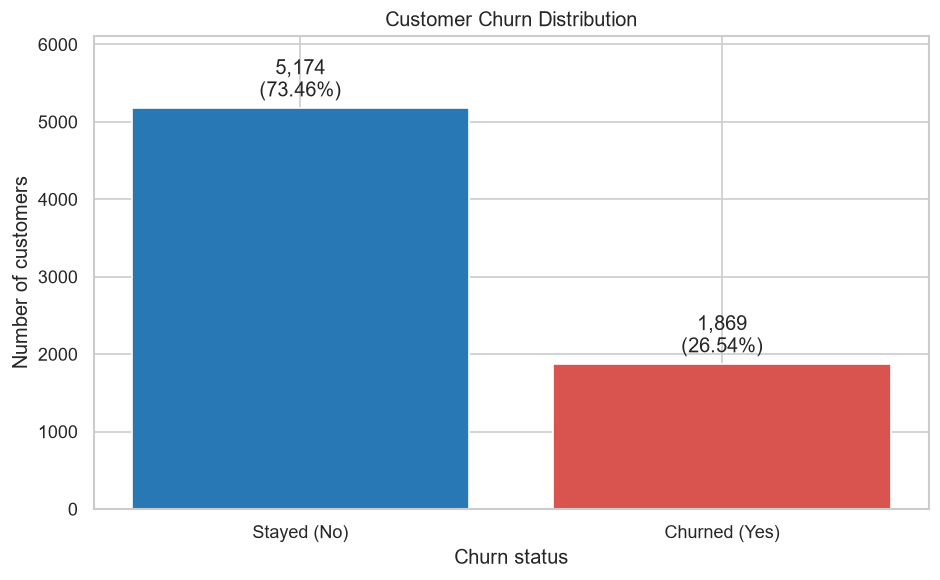

Chart saved successfully.


In [9]:
churn_counts = df_clean["Churn"].value_counts().reindex(["No", "Yes"])
churn_percentages = churn_counts / churn_counts.sum() * 100

churn_summary = pd.DataFrame({
    "Customer count": churn_counts,
    "Percentage": churn_percentages.round(2)
})

display(churn_summary)

figures_folder = project_folder / "reports" / "figures"
figures_folder.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["Stayed (No)", "Churned (Yes)"],
    churn_counts.values,
    color=["#2878B5", "#D9534F"]
)

ax.set_title("Customer Churn Distribution")
ax.set_xlabel("Churn status")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, churn_counts.max() * 1.18)

for bar, count, percentage in zip(
    bars, churn_counts.values, churn_percentages.values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 80,
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom"
    )

fig.tight_layout()
fig.savefig(
    figures_folder / "01_churn_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully.")

### Observations and business takeaway

- Of 7,043 customers, 1,869 churned (26.54%) and 5,174 stayed (73.46%).
- Approximately one in four customers in this dataset churned.
- This overall rate provides a baseline for comparing churn across
  contract types, tenure groups, and monthly charges.
- The distribution alone does not identify why customers churn.
  Segment-level analysis is needed before recommending targeted
  retention actions.

### Limitation

These percentages describe this dataset. They should not automatically
be treated as the churn rate for other companies or time periods.

## 5. Churn Rate by Contract Type

This analysis compares the percentage of customers who churned
within each contract category.

Churn rate = churned customers in a category / all customers
in that category × 100.

,Total customers,Churned customers,Churn rate (%)
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


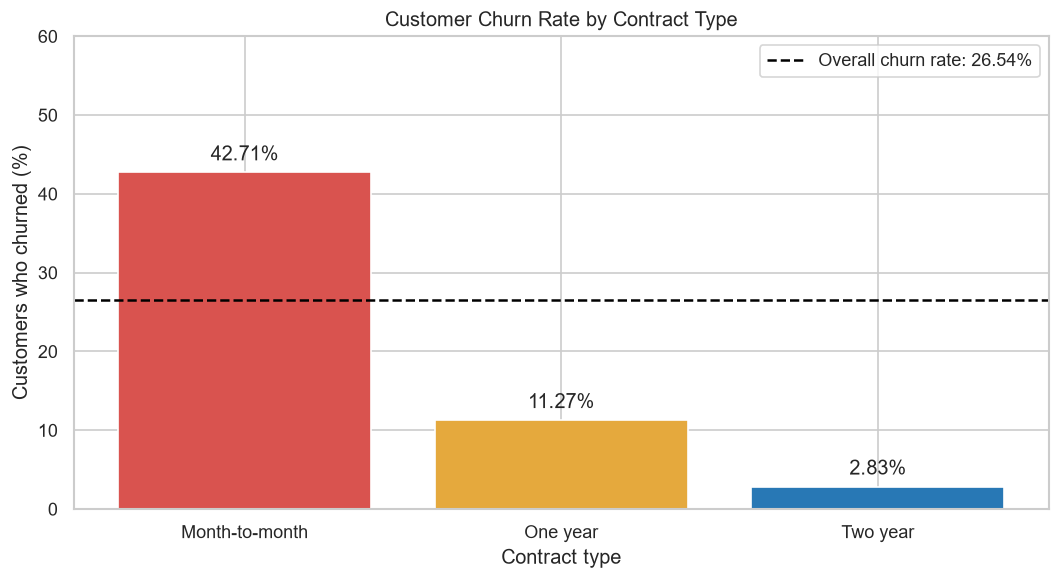

Contract chart saved successfully.


In [10]:
contract_order = ["Month-to-month", "One year", "Two year"]

contract_counts = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"]
).reindex(index=contract_order, columns=["No", "Yes"], fill_value=0)

contract_summary = pd.DataFrame({
    "Total customers": contract_counts.sum(axis=1),
    "Churned customers": contract_counts["Yes"]
})

contract_summary["Churn rate (%)"] = (
    contract_summary["Churned customers"]
    / contract_summary["Total customers"]
    * 100
)

display(contract_summary.round(2))

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    contract_summary.index,
    contract_summary["Churn rate (%)"],
    color=["#D9534F", "#E5A93D", "#2878B5"]
)

overall_churn_rate = df_clean["Churn"].eq("Yes").mean() * 100

ax.axhline(
    overall_churn_rate,
    color="black",
    linestyle="--",
    label=f"Overall churn rate: {overall_churn_rate:.2f}%"
)

ax.set_title("Customer Churn Rate by Contract Type")
ax.set_xlabel("Contract type")
ax.set_ylabel("Customers who churned (%)")
ax.set_ylim(0, 60)
ax.legend()

for bar, rate in zip(bars, contract_summary["Churn rate (%)"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{rate:.2f}%",
        ha="center",
        va="bottom"
    )

fig.tight_layout()
fig.savefig(
    figures_folder / "02_churn_by_contract.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Contract chart saved successfully.")

### Observations

- Month-to-month customers have the highest observed churn rate:
  42.71%, compared with the overall rate of 26.54%.
- One-year customers have a churn rate of 11.27%, while two-year
  customers have the lowest rate at 2.83%.
- The difference between month-to-month and two-year customers
  is 39.88 percentage points.

### Business takeaway

Month-to-month customers are a priority group for investigating
retention opportunities. Possible actions to test include better
onboarding, service support, and voluntary longer-term plan incentives.

### Limitation

These results show an association, not proof that longer contracts
cause lower churn. The groups may also differ in tenure, pricing,
services, or other characteristics.

## 6. Customer Tenure and Churn

This section compares customer tenure between retained and
churned customers using summary statistics and a box plot.

,count,mean,median,min,max
Churn,,,,,
No,5174,37.57,38.0,0,72
Yes,1869,17.98,10.0,1,72


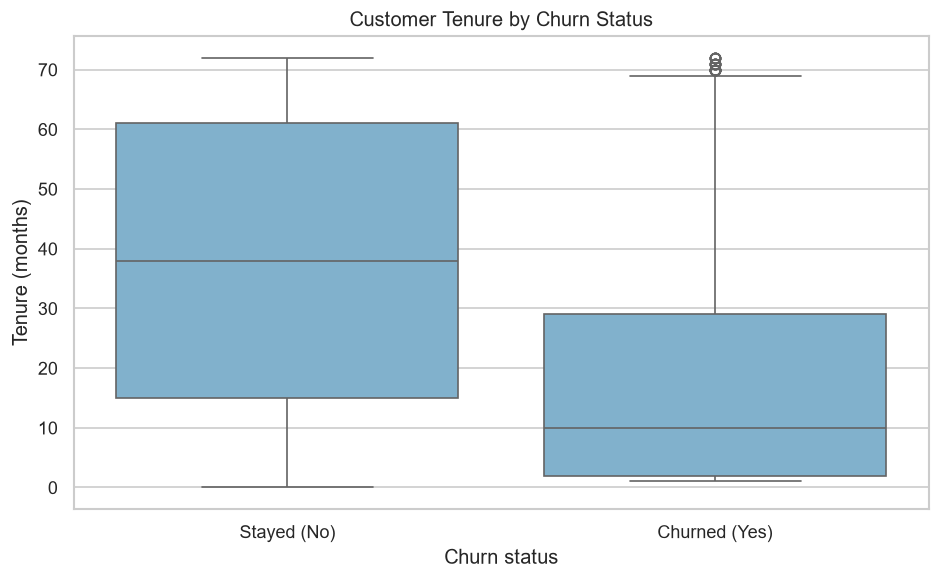

Tenure chart saved successfully.


In [11]:
tenure_summary = (
    df_clean.groupby("Churn")["tenure"]
    .agg(["count", "mean", "median", "min", "max"])
    .reindex(["No", "Yes"])
)

display(tenure_summary.round(2))

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="tenure",
    order=["No", "Yes"],
    color="#75B5D8",
    ax=ax
)

ax.set_title("Customer Tenure by Churn Status")
ax.set_xlabel("Churn status")
ax.set_ylabel("Tenure (months)")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Stayed (No)", "Churned (Yes)"])

fig.tight_layout()
fig.savefig(
    figures_folder / "03_tenure_by_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Tenure chart saved successfully.")

### Observations

- Customers who churned had a mean tenure of 17.98 months,
  compared with 37.57 months among customers who stayed.
- Median tenure was 10 months for churned customers and
  38 months for retained customers.
- Both comparisons show that churned customers generally
  had shorter tenure in this dataset.

### Business takeaway

Early customer experience is a useful area for further investigation.
Potential retention measures to test include onboarding support,
early service-quality checks, and timely resolution of billing issues.

### Limitation

This comparison does not establish that short tenure causes churn.
It also does not directly measure churn rates within tenure groups.
Other characteristics, such as contract type, may contribute
to the observed difference.

## 7. Monthly Charges and Churn

This section compares monthly charges between customers who
stayed and customers who churned.

,count,mean,median,min,max
Churn,,,,,
No,5174,61.27,64.43,18.25,118.75
Yes,1869,74.44,79.65,18.85,118.35


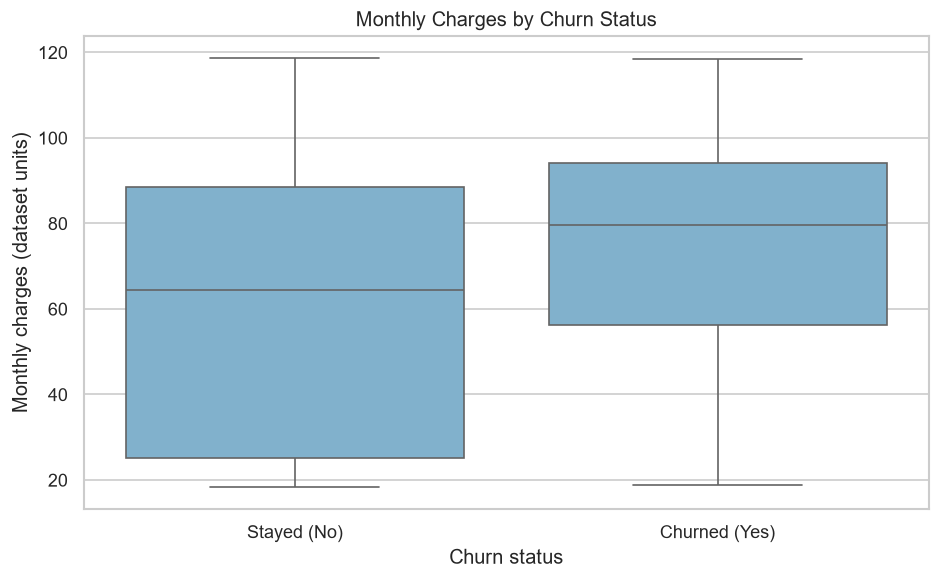

Monthly charges chart saved successfully.


In [12]:
charges_summary = (
    df_clean.groupby("Churn")["MonthlyCharges"]
    .agg(["count", "mean", "median", "min", "max"])
    .reindex(["No", "Yes"])
)

display(charges_summary.round(2))

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="MonthlyCharges",
    order=["No", "Yes"],
    color="#75B5D8",
    ax=ax
)

ax.set_title("Monthly Charges by Churn Status")
ax.set_xlabel("Churn status")
ax.set_ylabel("Monthly charges (dataset units)")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Stayed (No)", "Churned (Yes)"])

fig.tight_layout()
fig.savefig(
    figures_folder / "04_monthly_charges_by_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Monthly charges chart saved successfully.")

### Observations

- Customers who churned had a mean monthly charge of 74.44,
  compared with 61.27 for customers who stayed.
- Median monthly charges were also higher among churned
  customers: 79.65 versus 64.43.
- These comparisons suggest an association between higher
  monthly charges and churn in this dataset.

### Business takeaway

Investigate whether customers on higher-priced plans receive
sufficient value and whether billing issues or unsuitable plans
contribute to dissatisfaction. Test targeted plan reviews before
recommending broad discounts.

### Limitation

These results do not prove that higher charges cause churn.
Service type, contract type, and other customer characteristics
may help explain the difference.

## 8. Correlation Analysis

The heatmap examines linear associations among tenure, monthly
charges, total charges, and churn.

Churn is encoded as 0 for customers who stayed and 1 for customers
who churned. Missing values are excluded separately for each pair
of variables.

Contract type remains a categorical variable and is examined
separately through contract-wise churn rates.

|

,tenure,MonthlyCharges,TotalCharges,ChurnFlag
tenure,1.000,0.248,0.826,-0.352
MonthlyCharges,0.248,1.000,0.651,0.193
TotalCharges,0.826,0.651,1.000,-0.199
ChurnFlag,-0.352,0.193,-0.199,1.000


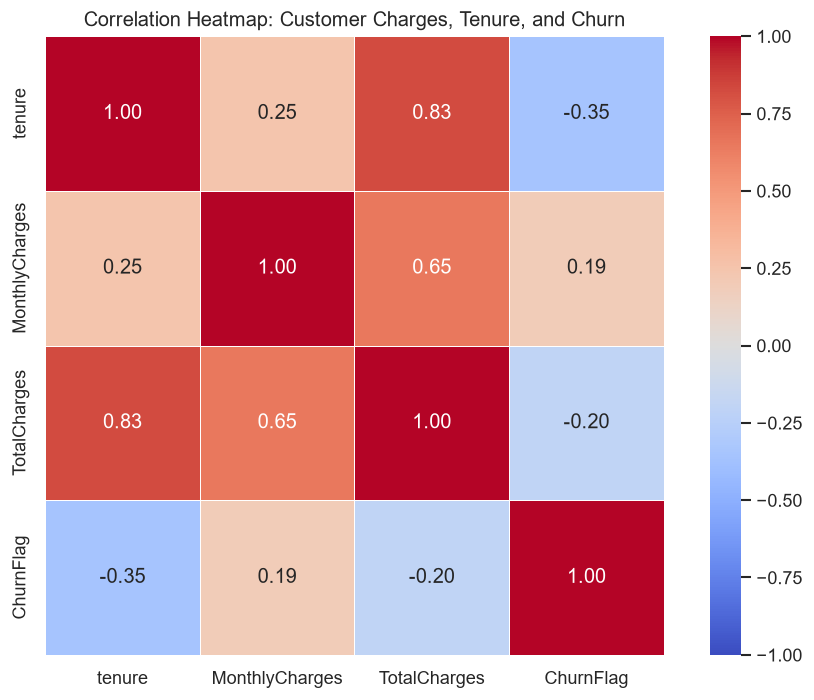

Correlations with churn:
tenure           -0.352
MonthlyCharges    0.193
TotalCharges     -0.199
Name: ChurnFlag, dtype: float64

Correlation heatmap saved successfully.


In [13]:
correlation_data = df_clean[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].copy()

correlation_data["ChurnFlag"] = (
    df_clean["Churn"].map({"No": 0, "Yes": 1})
)

correlation_matrix = correlation_data.corr()

display(correlation_matrix.round(3))

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    ax=ax
)

ax.set_title("Correlation Heatmap: Customer Charges, Tenure, and Churn")

fig.tight_layout()
fig.savefig(
    figures_folder / "05_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Correlations with churn:")
print(
    correlation_matrix["ChurnFlag"]
    .drop("ChurnFlag")
    .round(3)
)

print("\nCorrelation heatmap saved successfully.")

### Observations

Churn is encoded as 0 for stayed and 1 for churned.

- Tenure has a negative correlation with churn (-0.352):
  longer tenure is associated with a lower tendency to churn.
- Monthly charges have a positive correlation with churn (0.193):
  higher charges are associated with a higher tendency to churn.
- Total charges have a negative correlation with churn (-0.199).
  This should be interpreted alongside tenure because accumulated
  charges also depend on how long a customer has been subscribed.
- Among these three numeric features, tenure has the largest
  absolute correlation with churn.

### Limitations

Correlation does not establish causation or isolate the effect
of one variable from other customer characteristics.

These coefficients describe linear associations. Contract type
is analyzed separately as a categorical variable.

Correlations involving TotalCharges exclude its 11 missing entries.
No missing charges were replaced with assumed values.

## 9. Descriptive Statistics

This table summarizes the distributions of tenure, monthly
charges, and total charges.

The count for TotalCharges excludes the 11 missing values.

In [14]:
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

numeric_summary = df_clean[numeric_columns].describe().T

display(numeric_summary.round(2))

tables_folder = project_folder / "reports" / "tables"
tables_folder.mkdir(parents=True, exist_ok=True)

numeric_summary.to_csv(tables_folder / "numeric_summary.csv")
churn_summary.to_csv(tables_folder / "churn_summary.csv")
contract_summary.to_csv(tables_folder / "contract_summary.csv")
tenure_summary.to_csv(tables_folder / "tenure_summary.csv")
charges_summary.to_csv(tables_folder / "monthly_charges_summary.csv")
correlation_matrix.to_csv(tables_folder / "correlation_matrix.csv")

print("Summary tables saved successfully.")

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.8,401.45,1397.475,3794.7375,8684.8


Summary tables saved successfully.


## 10. Conclusions and Suggested Next Steps

### Main findings

1. Overall churn was 26.54%: 1,869 of 7,043 customers churned.
2. Month-to-month customers had a churn rate of 42.71%,
   compared with 11.27% for one-year contracts and 2.83%
   for two-year contracts.
3. Churned customers had shorter median tenure:
   10 months versus 38 months among retained customers.
4. Churned customers had higher mean monthly charges:
   74.44 versus 61.27 among retained customers.
5. Tenure had the largest absolute correlation with churn
   among the three numeric features examined (-0.352).

### Suggested retention experiments

- Test improved onboarding and early customer-support check-ins.
- Investigate service and billing concerns among month-to-month customers.
- Test voluntary longer-term plan incentives without assuming
  that changing contract length alone will prevent churn.
- Review plan suitability and perceived value for higher-charge customers.

### Limitations

- Findings are observational and do not establish causation.
- Comparisons do not control for differences between customer groups.
- TotalCharges contains 11 missing values, which were retained
  as missing rather than replaced with assumed charges.
- Findings describe this dataset and may not generalize to
  other companies or time periods.
- No predictive model was trained; this project focuses on
  exploratory data analysis.